In [5]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel, Matern
from scipy.stats import norm
from scipy.optimize import minimize
import warnings
warnings.filterwarnings('ignore')
from scipy.interpolate import griddata

In [ ]:
X = np.load('..\Function_2_Data\Week_2_Data/F2_Week_2_inputs.npy')
Y = np.load('..\Function_2_Data\Week_2_Data/F2_Week_2_outputs.npy')

In [7]:
Y_max=Y[0:-1].max()
Y_max_new=Y.max()
Y_max, Y_max_new

(np.float64(0.6112052157614438), np.float64(0.6112052157614438))

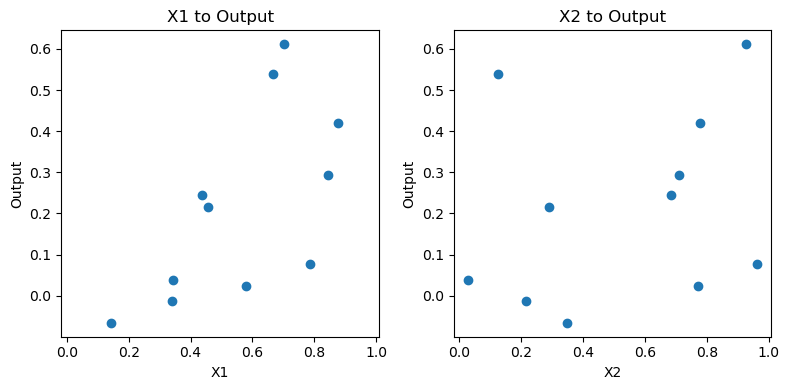

In [54]:
# Create 2 subplots
fig, axes = plt.subplots(1, 2, figsize=(8, 4), sharex=True)

# Scatterplot of first array
axes[0].scatter(X[:,0], Y)
axes[0].set_title('X1 to Output')
axes[0].set_xlabel('X1')
axes[0].set_ylabel('Output')

# Scatterplot of second array
axes[1].scatter(X[:,1], Y)
axes[1].set_title('X2 to Output')
axes[1].set_xlabel('X2')
axes[1].set_ylabel('Output')

plt.tight_layout()
plt.show()

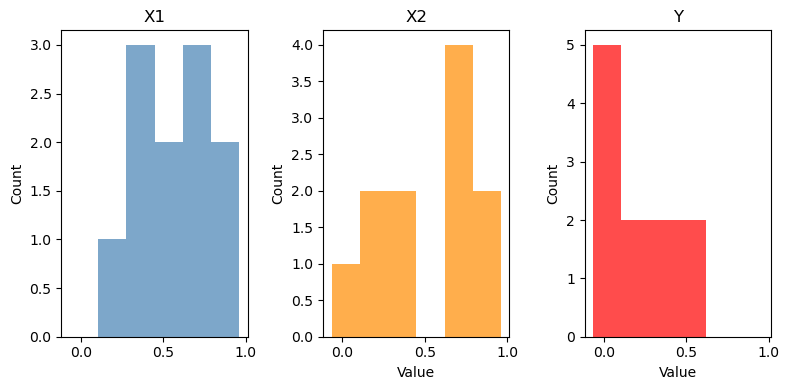

In [55]:
# Create 3 subplots
fig, axes = plt.subplots(1, 3, figsize=(8, 4), sharex=True)

# Use common bins for easy comparison
bins = np.linspace(
    min(X[:,0].min(), X[:,1].min(), Y.min()),
    max(X[:,0].max(), X[:,1].max(), Y.max()),
    7
)

# Histogram of first array
axes[0].hist(X[:,0], bins=bins, color='steelblue', alpha=0.7)
axes[0].set_title('X1')
axes[0].set_ylabel('Count')

# Histogram of second array
axes[1].hist(X[:,1], bins=bins, color='darkorange', alpha=0.7)
axes[1].set_title('X2')
axes[1].set_xlabel('Value')
axes[1].set_ylabel('Count')

# Histogram of target
axes[2].hist(Y, bins=bins, color='red', alpha=0.7)
axes[2].set_title('Y')
axes[2].set_xlabel('Value')
axes[2].set_ylabel('Count')

plt.tight_layout()
plt.show()

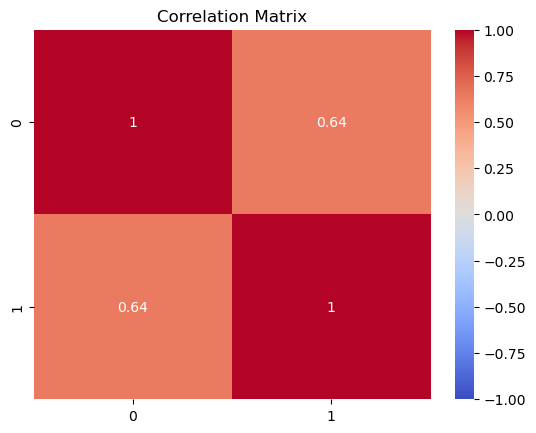

In [57]:
import seaborn as sns
import pandas as pd
df=pd.DataFrame(data=X)
corr = df.corr()

sns.heatmap(corr,
            annot=True,
            cmap='coolwarm',
            vmin=-1,
            vmax=1)

plt.title("Correlation Matrix")
plt.show()

In [58]:
#kernel = Matern(length_scale=[1.0, 1.0])
kernel = ConstantKernel(1.0) * RBF(length_scale=[1.0, 1.0])
gp = GaussianProcessRegressor(kernel=kernel, alpha=1e-6, n_restarts_optimizer=10)
gp.fit(X, Y)

,kernel,"1**2 * RBF(le..._scale=[1, 1])"
,alpha,1e-06
,optimizer,'fmin_l_bfgs_b'
,n_restarts_optimizer,10
,normalize_y,False
,copy_X_train,True
,n_targets,None
,random_state,None
,kernel__k1,1**2
,kernel__k2,"RBF(length_scale=[1, 1])"
,kernel__k1__constant_value,1.0


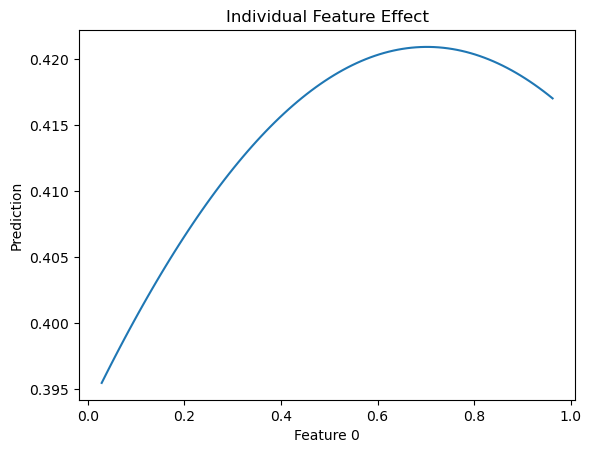

In [70]:
sample = X[1].copy()

feature = 1

values = np.linspace(
    X[:, feature].min(),
    X[:, feature].max(),
    100
)

predictions = []

for v in values:
    temp = sample.copy()
    temp[feature] = v
    pred = gp.predict(temp.reshape(1, -1))[0]
    predictions.append(pred)

plt.plot(values, predictions)
plt.xlabel("Feature 0")
plt.ylabel("Prediction")
plt.title("Individual Feature Effect")
plt.show()

In [59]:
def upper_confidence_bound(mu, sigma, kappa=2.0):
    """
    Upper Confidence Bound (UCB) acquisition function.
    
    UCB = mean + kappa * std
    
    Parameters:
    -----------
    mu : predicted mean
    sigma : predicted standard deviation
    kappa : exploration parameter (higher = more exploration)
    """
    return mu + kappa * sigma

def lower_confidence_bound(mu, sigma, kappa=2.0):
    """
    Lower Confidence Bound (UCB) acquisition function.
    LCB = mean - kappa * std
    Parameters:
    -----------
    mu : predicted mean
    sigma : predicted standard deviation
    kappa : exploration parameter (higher = more exploration)
    """
    return mu - kappa * sigma

def expected_improvement(mu, sigma, y_best, xi=0.01):
    """
    Expected Improvement (EI) acquisition function.
    
    EI = E[max(f(x) - f(x_best), 0)]
    
    Parameters:
    -----------
    mu : predicted mean
    sigma : predicted standard deviation  
    y_best : best observed value so far
    xi : exploration parameter
    """
    with np.errstate(divide='warn'):
        improvement = mu - y_best - xi
        Z = improvement / sigma
        ei = improvement * norm.cdf(Z) + sigma * norm.pdf(Z)
        ei[sigma == 0.0] = 0.0
    return ei


In [60]:
def acq_objective(X):
    X = X.reshape(1, -1)
    mu, sigma = gp.predict(X, return_std=True)
               
    if acquisition == 'ei':
        acq_val = expected_improvement(mu, sigma, Y.max())
    elif acquisition == 'lcb':
        acq_val = lower_confidence_bound(mu, sigma, kappa=2.5)
    else:
        acq_val = upper_confidence_bound(mu, sigma, kappa=2.5)
           
    return -acq_val  # Negative because we use the 'minimize' function later

In [61]:
acquisition='lcb'
n_dims=X.shape[1]
bounds = [(0, 1) for _ in range(n_dims)]
best_acq = np.inf
X_next = None

for _ in range(10):  # Multiple random starts
    x0 = np.random.uniform([b[0] for b in bounds], [b[1] for b in bounds])
    result = minimize(acq_objective, x0, bounds=bounds, method='L-BFGS-B')
    if result.fun < best_acq:
        best_acq = result.fun
        X_next = result.x

np.set_printoptions(suppress=True, precision=6)
print(f'New query: {X_next[0]:.6f}-{X_next[1]:.6f}')

New query: 0.702119-0.919585


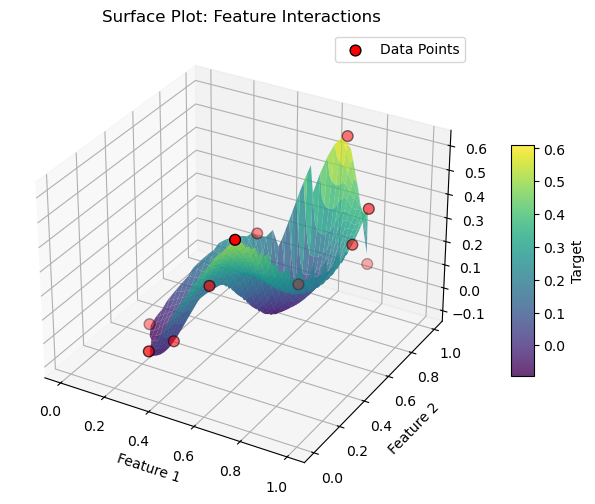

In [62]:
# **3D Surface Plot (Separate Block for Feature Interaction)**

x, y = X[:, 0], X[:, 1]
z = Y

# Create grid points for interpolation
grid_x, grid_y = np.meshgrid(
    np.linspace(0, 1, 100),
    np.linspace(0, 1, 100)
)

# Interpolate the Z values for the grid
grid_z = griddata(
    (x, y), z, 
    (grid_x, grid_y), 
    method="cubic"
)

# Plotting the surface
fig = plt.figure(figsize=(10, 6))
ax = fig.add_subplot(111, projection="3d")
surf = ax.plot_surface(
    grid_x, grid_y, grid_z, 
    cmap="viridis", 
    edgecolor="none", 
    alpha=0.8
)
# Scatter points (data points)
ax.scatter(x, y, z, color='red', edgecolor='black', s=60, label="Data Points")
ax.legend(loc="best")  # Add legend for clarity

cb = fig.colorbar(surf, ax=ax, shrink=0.5, aspect=10)
cb.set_label("Target")
ax.set_xlabel("Feature 1")
ax.set_ylabel("Feature 2")
plt.title("Surface Plot: Feature Interactions")
plt.show()